<a href="https://colab.research.google.com/github/JoaoMAraujoJr/DeepLearning-Resolu-es/blob/main/10_object_detection_resolu%C3%A7%C3%A3o.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Detecção de Objetos

Um classificador responde **o que** há na imagem. Um detector responde **o que** há e **onde**: a saída é uma lista de **caixas delimitadoras** (*bounding boxes*), cada uma com uma classe e uma confiança, e a imagem pode ter vários objetos.

Vamos treinar do zero um detector inspirado no **YOLO** (*You Only Look Once*), que prevê todas as caixas de uma vez com uma rede convolucional. Os dados são sintéticos: dígitos do MNIST espalhados em uma imagem maior.

In [17]:
import random

import matplotlib.patches as patches
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


## O dataset sintético

Cada imagem tem $112 \times 112$ pixels e de 1 a 4 dígitos do MNIST, com tamanhos entre 28 e 56 pixels, colados em posições sorteadas sem se sobrepor. Como somos nós que colamos os dígitos, as anotações vêm de graça.

Cada caixa é guardada como `(classe, x, y, w, h)`: $(x, y)$ é o centro e $(w, h)$ são a largura e a altura, todos divididos pelo tamanho da imagem, entre 0 e 1. É o formato usado pelo YOLO.

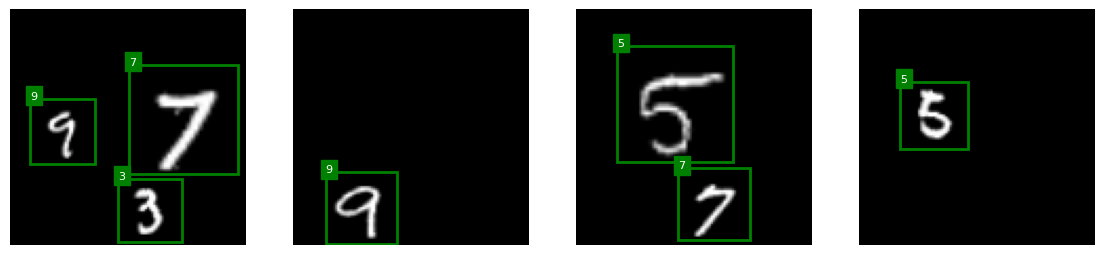

In [18]:
IMAGE_SIZE = 112

mnist_train = datasets.MNIST(root="data", train=True, download=True, transform=transforms.ToTensor())
mnist_test = datasets.MNIST(root="data", train=False, download=True, transform=transforms.ToTensor())


def overlaps(a, b):
    ax, ay, a_size = a
    bx, by, b_size = b
    return ax < bx + b_size and bx < ax + a_size and ay < by + b_size and by < ay + a_size


def make_image(mnist, rng, max_digits=4):
    image = torch.zeros(1, IMAGE_SIZE, IMAGE_SIZE)
    placed = []   # (x0, y0, tamanho) em pixels
    boxes = []    # (classe, x, y, w, h) entre 0 e 1

    n_digits = rng.randint(1, max_digits)
    for _ in range(100):   # tentativas
        if len(boxes) == n_digits:
            break

        size = rng.randint(28, 56)
        x0 = rng.randint(0, IMAGE_SIZE - size)
        y0 = rng.randint(0, IMAGE_SIZE - size)
        if any(overlaps((x0, y0, size), other) for other in placed):
            continue

        digit, label = mnist[rng.randrange(len(mnist))]                             # [1, 28, 28]
        digit = F.interpolate(digit[None], size=(size, size), mode="bilinear")[0]   # [1, size, size]
        image[:, y0:y0 + size, x0:x0 + size] = digit

        placed.append((x0, y0, size))
        x = (x0 + size / 2) / IMAGE_SIZE
        y = (y0 + size / 2) / IMAGE_SIZE
        boxes.append((label, x, y, size / IMAGE_SIZE, size / IMAGE_SIZE))

    return image, boxes


def draw_boxes(ax, boxes, color, show_labels=True):
    for box in boxes:
        label, x, y, w, h = box[0], *box[-4:]   # aceita também (classe, confiança, x, y, w, h)
        x0 = (x - w / 2) * IMAGE_SIZE
        y0 = (y - h / 2) * IMAGE_SIZE
        ax.add_patch(patches.Rectangle((x0, y0), w * IMAGE_SIZE, h * IMAGE_SIZE,
                                       linewidth=2, edgecolor=color, facecolor="none"))
        if show_labels:
            ax.text(x0, y0, str(label), color="white", backgroundcolor=color, fontsize=8)


rng = random.Random(0)
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax in axes:
    image, boxes = make_image(mnist_train, rng)
    ax.imshow(image[0], cmap="gray")
    draw_boxes(ax, boxes, "green")
    ax.axis("off")
plt.show()

## A grade do YOLO

A rede tem uma saída de tamanho fixo, mas cada imagem tem um número diferente de objetos. O YOLO divide a imagem em uma **grade** de $S \times S$ células, e cada célula responde pelo objeto cujo **centro** cai dentro dela. Cada célula prevê:

- $p$: a confiança de que há um objeto centrado nela;
- $x, y$: o centro do objeto, **relativo à célula**, entre 0 e 1;
- $w, h$: a largura e a altura, relativas à imagem;
- $c_0, \dots, c_9$: os escores das 10 classes.

Com $S = 7$, cada célula cobre $16 \times 16$ pixels e o alvo é um tensor $7 \times 7 \times 15$. Um objeto com centro $(x, y)$ cai na célula da linha $i$ e coluna $j$:

$$
i = \lfloor y \cdot S \rfloor, \qquad j = \lfloor x \cdot S \rfloor, \qquad x_{cel} = x \cdot S - j, \qquad y_{cel} = y \cdot S - i
$$

Cada célula guarda um objeto só. Aqui isso basta: como os dígitos não se sobrepõem e têm pelo menos 28 pixels, dois centros não caem na mesma célula.

A função `grid_to_boxes` faz o caminho inverso, mantendo as células com $p$ acima de um limiar. É ela que vamos usar na saída da rede.

In [19]:
S = 7
NUM_CLASSES = 10


def boxes_to_grid(boxes):
    grid = torch.zeros(S, S, 5 + NUM_CLASSES)   # [7, 7, 15]
    for label, x, y, w, h in boxes:
        i = int(y * S)
        j = int(x * S)
        grid[i, j, 0] = 1                                    # p
        grid[i, j, 1:5] = torch.tensor([x * S - j, y * S - i, w, h])
        grid[i, j, 5 + label] = 1                            # classe em one-hot
    return grid


def grid_to_boxes(grid, threshold=0.5):
    boxes = []
    for i in range(S):
        for j in range(S):
            p = grid[i, j, 0].item()
            if p < threshold:
                continue
            x_cell, y_cell, w, h = grid[i, j, 1:5].tolist()
            label = grid[i, j, 5:].argmax().item()
            boxes.append((label, p, (j + x_cell) / S, (i + y_cell) / S, w, h))
    return boxes

O `Dataset` gera cada imagem na hora, sem nada salvo em disco. A semente do sorteio depende do índice, então a imagem `idx` é sempre a mesma. O treino usa dígitos do treino do MNIST e o teste, dígitos do teste.

In [20]:
class SyntheticMNIST(Dataset):
    def __init__(self, mnist, num_images, seed):
        self.mnist = mnist
        self.num_images = num_images
        self.seed = seed

    def __len__(self):
        return self.num_images

    def __getitem__(self, idx):
        rng = random.Random(self.seed * 1_000_000 + idx)
        image, boxes = make_image(self.mnist, rng)
        return image, boxes_to_grid(boxes)


train_set = SyntheticMNIST(mnist_train, num_images=20000, seed=0)
test_set = SyntheticMNIST(mnist_test, num_images=1000, seed=1)

train_dataloader = DataLoader(train_set, batch_size=64, shuffle=True, num_workers=2)
test_dataloader = DataLoader(test_set, batch_size=200)

images, targets = next(iter(train_dataloader))
print(images.shape)    # [64, 1, 112, 112]
print(targets.shape)   # [64, 7, 7, 15]

torch.Size([64, 1, 112, 112])
torch.Size([64, 7, 7, 15])


Desenhando as caixas recuperadas do alvo com `grid_to_boxes`, junto com as linhas da grade:

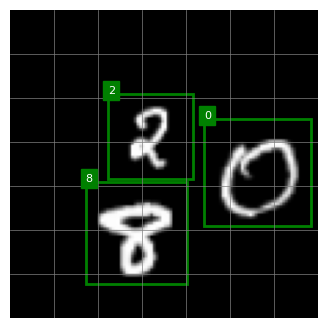

In [21]:
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(images[0, 0], cmap="gray")
for k in range(1, S):
    ax.axhline(k * IMAGE_SIZE / S - 0.5, color="gray", linewidth=0.5)
    ax.axvline(k * IMAGE_SIZE / S - 0.5, color="gray", linewidth=0.5)
draw_boxes(ax, grid_to_boxes(targets[0]), "green")
ax.axis("off")
plt.show()

## O detector

O detector não termina com `Flatten` e `Linear`: ele é **totalmente convolucional**. Quatro blocos de convolução e pooling reduzem a imagem de $112 \times 112$ para $7 \times 7$, o tamanho da grade, e cada posição do mapa final corresponde a uma célula.

A última camada é uma convolução $1 \times 1$, que aplica a mesma camada linear em cada posição e leva os 128 canais aos 15 valores da célula. O `permute` passa os canais para o fim, no formato do alvo. A rede devolve valores sem ativação, como os logits de um classificador.

In [22]:
def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )


class Detector(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(1, 16),     # [N, 16, 56, 56]
            conv_block(16, 32),    # [N, 32, 28, 28]
            conv_block(32, 64),    # [N, 64, 14, 14]
            conv_block(64, 128),   # [N, 128, 7, 7]
        )
        self.head = nn.Sequential(
            nn.Conv2d(128, 128, kernel_size=3, padding=1),   # [N, 128, 7, 7]
            nn.ReLU(),
            nn.Conv2d(128, 5 + NUM_CLASSES, kernel_size=1),  # [N, 15, 7, 7]
        )

    def forward(self, x):
        x = self.head(self.features(x))
        return x.permute(0, 2, 3, 1)                         # [N, 7, 7, 15]


model = Detector()
print(model(images).shape)   # [64, 7, 7, 15]

torch.Size([64, 7, 7, 15])


## A função de perda

A perda tem três partes, uma para cada pergunta que a célula responde:

- **tem objeto?** Entropia cruzada binária na confiança, em todas as células. Como a maioria das células está vazia, elas recebem o peso $\lambda_{noobj} = 0{,}5$, para a rede não aprender a dizer sempre "não";
- **onde está?** Erro quadrático nas coordenadas, passadas pela sigmoide, só nas células com objeto. Recebe o peso $\lambda_{coord} = 5$;
- **qual dígito?** Entropia cruzada nas classes, só nas células com objeto.

$$
\mathcal{L} = \lambda_{coord} \sum_{\text{obj}} \left\| b - \hat{b} \right\|^2
+ \sum_{\text{obj}} \text{BCE}(1, \hat{p})
+ \lambda_{noobj} \sum_{\text{noobj}} \text{BCE}(0, \hat{p})
+ \sum_{\text{obj}} \text{CE}(c, \hat{c})
$$

em que $b = (x, y, w, h)$ é a caixa, $\sum_{\text{obj}}$ soma sobre as células com objeto e $\sum_{\text{noobj}}$ sobre as vazias. O total é dividido pelo tamanho do lote.

In [23]:
def detection_loss(predictions, targets, lambda_coord=5.0, lambda_noobj=0.5):
    has_object = targets[..., 0] == 1   # [N, 7, 7]
    pred = predictions[has_object]      # [n_obj, 15], só as células com objeto
    true = targets[has_object]

    confidence = F.binary_cross_entropy_with_logits(predictions[..., 0], targets[..., 0], reduction="none")
    object_loss = confidence[has_object].sum()
    no_object_loss = confidence[~has_object].sum()

    box_loss = F.mse_loss(pred[:, 1:5].sigmoid(), true[:, 1:5], reduction="sum")
    class_loss = F.cross_entropy(pred[:, 5:], true[:, 5:].argmax(dim=1), reduction="sum")

    total = lambda_coord * box_loss + object_loss + lambda_noobj * no_object_loss + class_loss
    return total / len(predictions)

## Treinamento

O laço é o mesmo dos classificadores, trocando a perda.

[1/10] perda 2.865
[2/10] perda 0.966
[3/10] perda 0.761
[4/10] perda 0.665
[5/10] perda 0.593
[6/10] perda 0.532
[7/10] perda 0.480
[8/10] perda 0.442
[9/10] perda 0.405
[10/10] perda 0.387


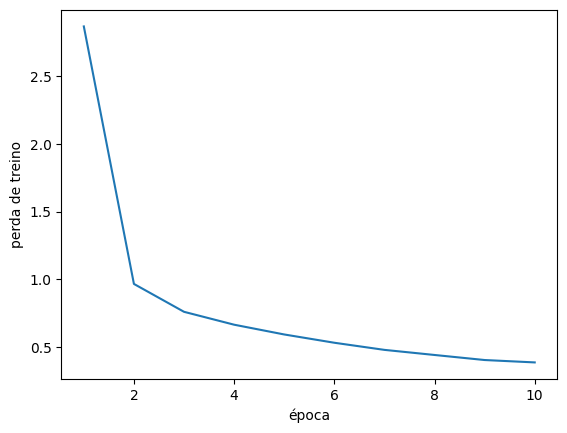

In [24]:
def train(model, train_dataloader, num_epochs, lr=1e-3):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    losses = []

    for epoch in range(num_epochs):
        model.train()
        total_loss = 0
        for images, targets in train_dataloader:
            images, targets = images.to(device), targets.to(device)
            loss = detection_loss(model(images), targets)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        losses.append(total_loss / len(train_dataloader))
        print(f"[{epoch + 1}/{num_epochs}] perda {losses[-1]:.3f}")

    return losses


num_epochs = 10

torch.manual_seed(42)
model = Detector().to(device)
losses = train(model, train_dataloader, num_epochs)

plt.plot(range(1, num_epochs + 1), losses)
plt.xlabel("época")
plt.ylabel("perda de treino")
plt.show()

## Das previsões às caixas

Na saída da rede, aplicamos a sigmoide na confiança e nas coordenadas e usamos a mesma `grid_to_boxes`. Só que um dígito grande ocupa várias células, e às vezes uma vizinha da célula responsável também acha que tem um objeto. O resultado são caixas repetidas sobre o mesmo dígito.

A **supressão de não máximos** (NMS, *non-maximum suppression*) remove as repetições: ordena as caixas pela confiança, guarda a primeira, apaga as da mesma classe que se sobrepõem muito a ela e repete com as que sobraram.

A sobreposição é medida pela **interseção sobre união** (IoU), a área em comum dividida pela área coberta pelas duas caixas. Vale 1 para caixas idênticas e 0 para caixas que não se tocam:

$$
\text{IoU}(A, B) = \frac{|A \cap B|}{|A| + |B| - |A \cap B|}
$$

In [25]:
def iou(box_a, box_b):
    ax, ay, aw, ah = box_a
    bx, by, bw, bh = box_b

    # bordas do retângulo de interseção
    left = max(ax - aw / 2, bx - bw / 2)
    right = min(ax + aw / 2, bx + bw / 2)
    top = max(ay - ah / 2, by - bh / 2)
    bottom = min(ay + ah / 2, by + bh / 2)

    intersection = max(0, right - left) * max(0, bottom - top)
    union = aw * ah + bw * bh - intersection
    return intersection / union


def non_max_suppression(boxes, iou_threshold=0.5):
    boxes = sorted(boxes, key=lambda box: box[1], reverse=True)   # maior confiança primeiro
    kept = []
    while boxes:
        best = boxes.pop(0)
        kept.append(best)
        boxes = [box for box in boxes
                 if box[0] != best[0] or iou(box[2:], best[2:]) < iou_threshold]
    return kept


def detect(model, images, threshold=0.5, iou_threshold=0.5):
    model.eval()
    with torch.no_grad():
        grids = model(images.to(device)).cpu()     # [N, 7, 7, 15]
    grids[..., 0:5] = grids[..., 0:5].sigmoid()    # p, x, y, w, h entre 0 e 1
    return [non_max_suppression(grid_to_boxes(grid, threshold), iou_threshold) for grid in grids]

Contando as caixas no lote de teste com um limiar de confiança baixo, sem e com NMS. Com `iou_threshold=1`, a NMS não apaga nada.

In [26]:
images, targets = next(iter(test_dataloader))
n_true = sum(len(grid_to_boxes(target)) for target in targets)

without_nms = detect(model, images, threshold=0.1, iou_threshold=1.0)
with_nms = detect(model, images, threshold=0.1)
print(f"{n_true} dígitos")
print(f"sem NMS: {sum(map(len, without_nms))} caixas")
print(f"com NMS: {sum(map(len, with_nms))} caixas")

511 dígitos
sem NMS: 599 caixas
com NMS: 514 caixas


## Resultados

Em verde, as caixas verdadeiras; em vermelho, as detecções com o limiar padrão de 0,5.

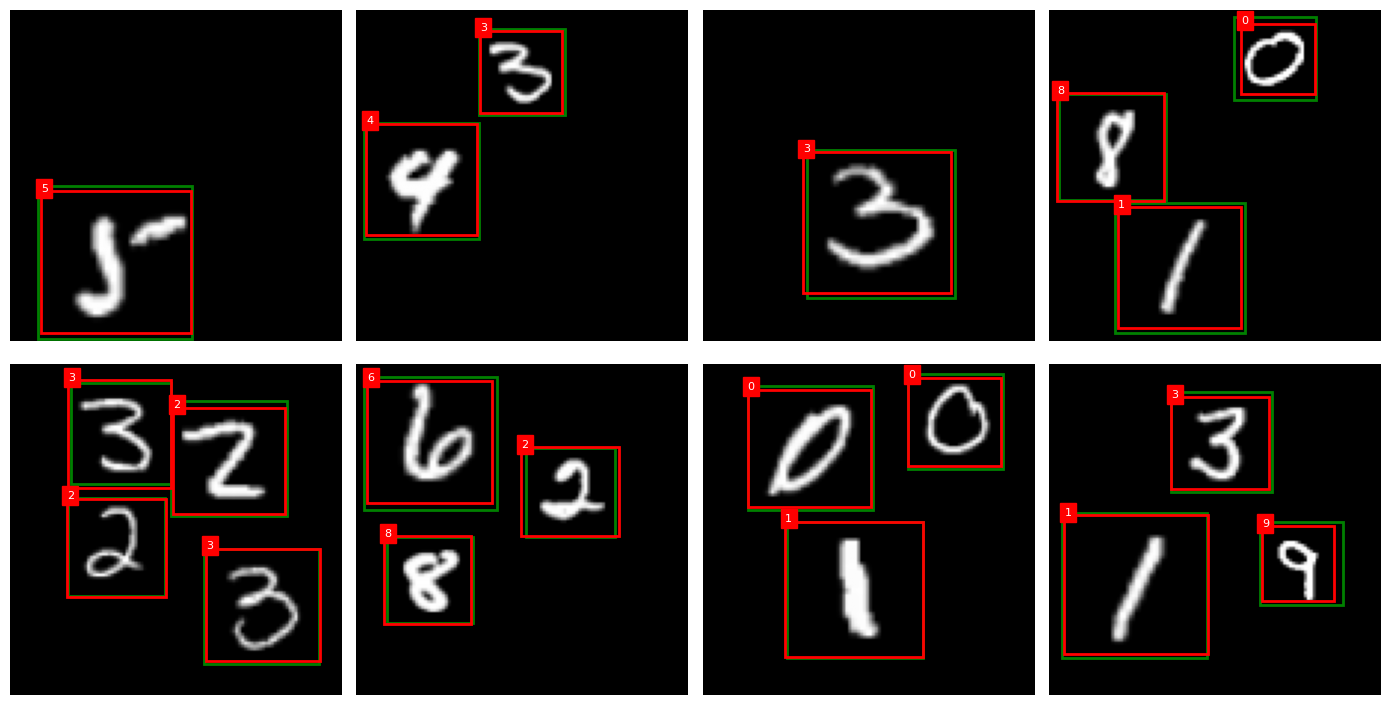

In [27]:
detections = detect(model, images)

fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
for k, ax in enumerate(axes.flat):
    ax.imshow(images[k, 0], cmap="gray")
    draw_boxes(ax, grid_to_boxes(targets[k]), "green", show_labels=False)
    draw_boxes(ax, detections[k], "red")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Exercícios

### Exercício 1: limiares

Mude o `threshold` e o `iou_threshold` da `detect` e refaça a figura dos resultados. Com quais valores aparecem caixas repetidas sobre o mesmo dígito? Com quais o detector começa a perder dígitos?


511 dígitos de verdade no lote

confiança=0.1, iou=0.3: 514 caixas


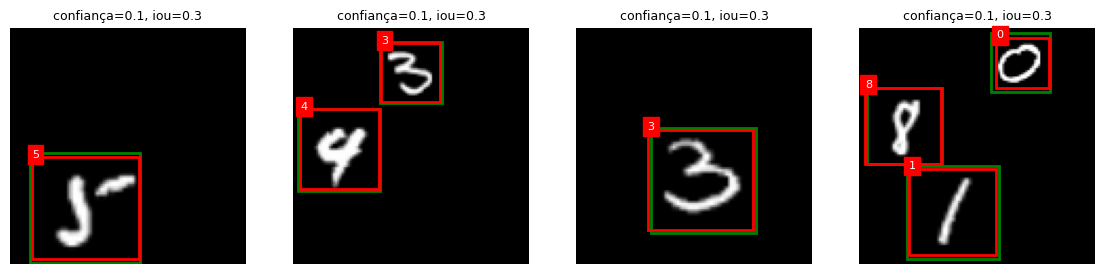

confiança=0.1, iou=0.5: 514 caixas


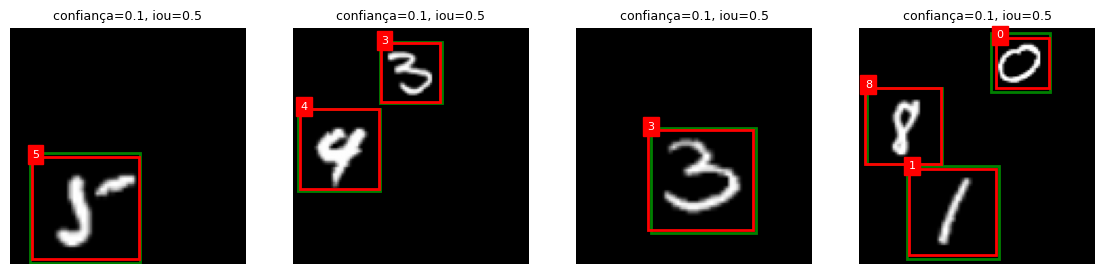

confiança=0.1, iou=0.75: 519 caixas


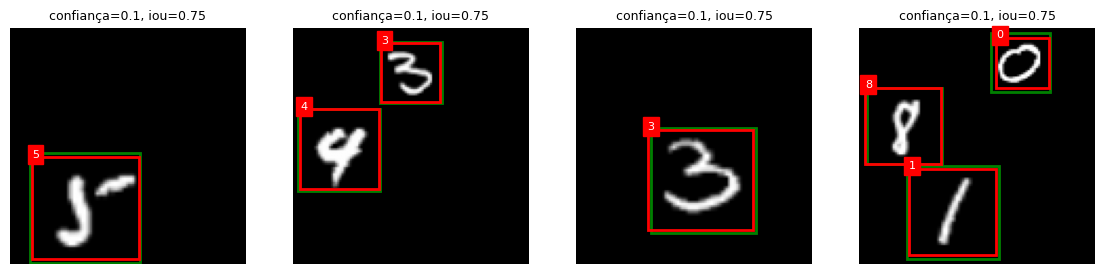

confiança=0.1, iou=1.0: 599 caixas


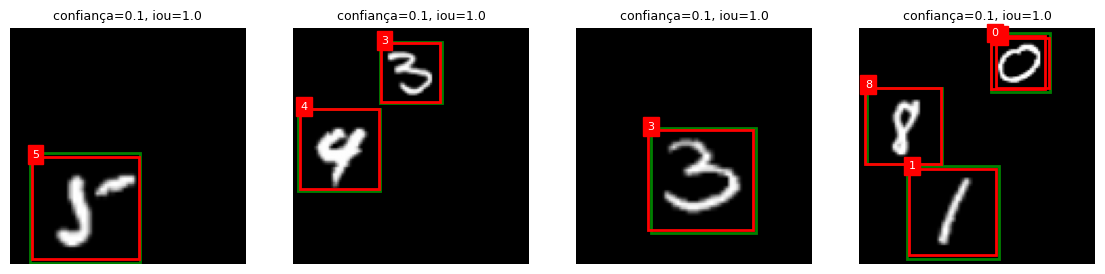

confiança=0.5, iou=0.3: 507 caixas


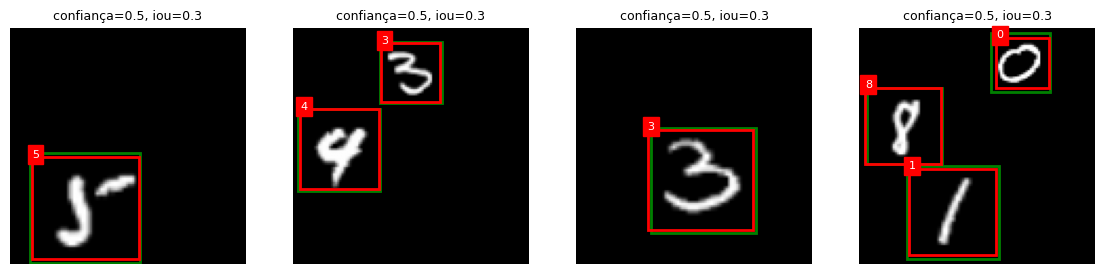

confiança=0.5, iou=0.5: 507 caixas


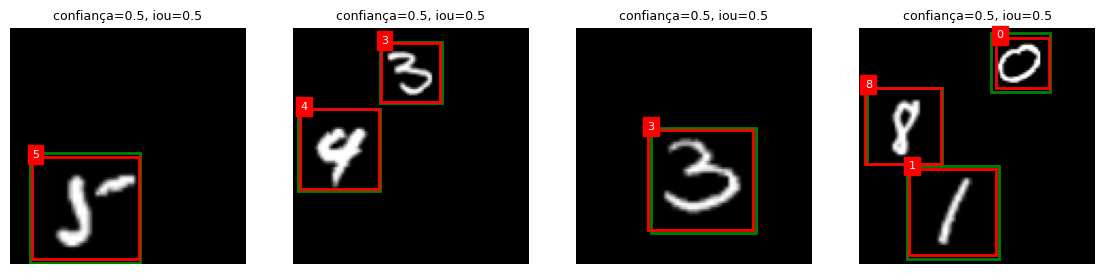

confiança=0.5, iou=0.75: 508 caixas


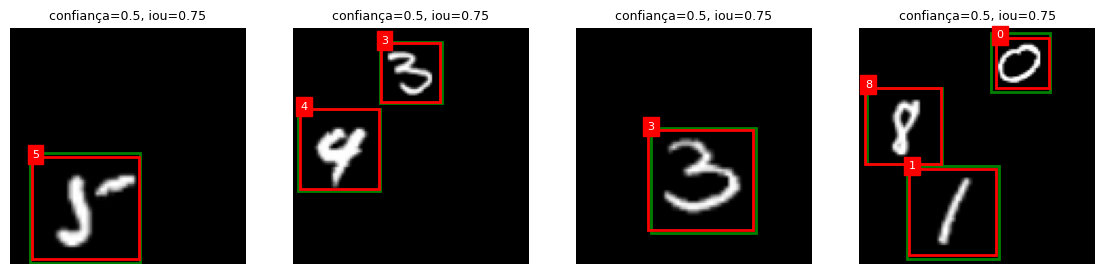

confiança=0.5, iou=1.0: 525 caixas


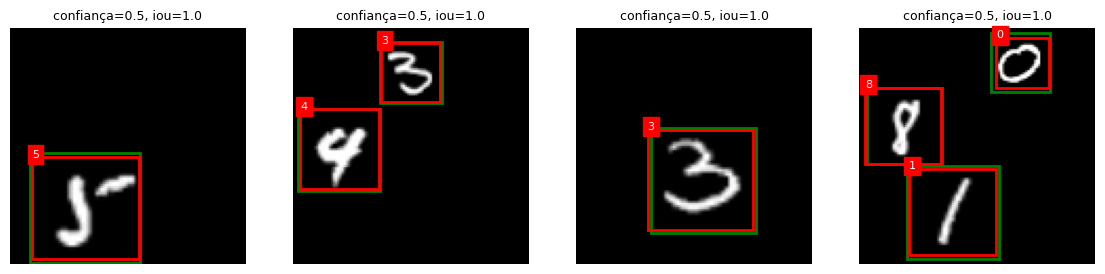

confiança=0.8, iou=0.3: 478 caixas


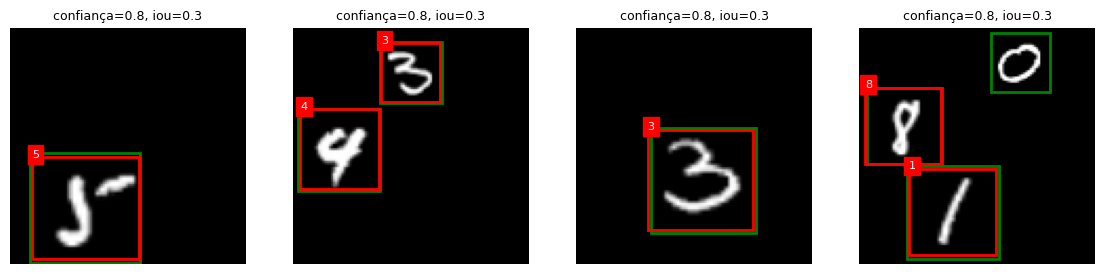

confiança=0.8, iou=0.5: 478 caixas


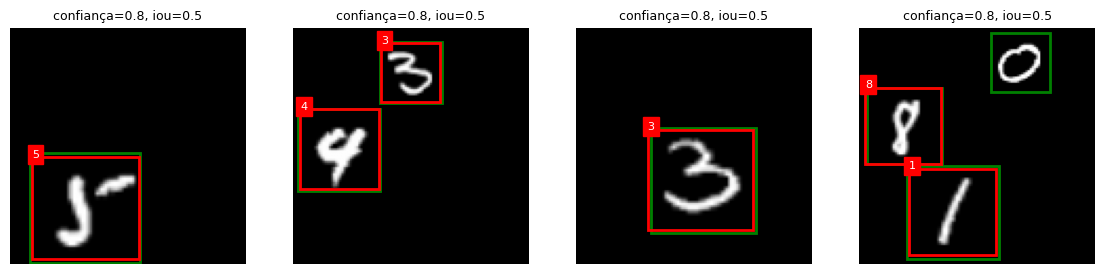

confiança=0.8, iou=0.75: 478 caixas


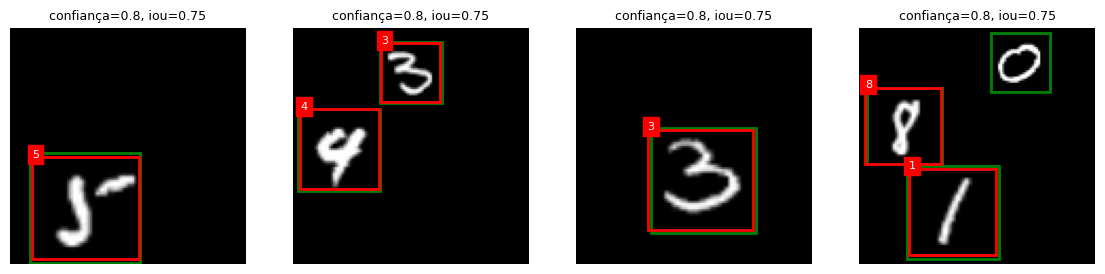

confiança=0.8, iou=1.0: 479 caixas


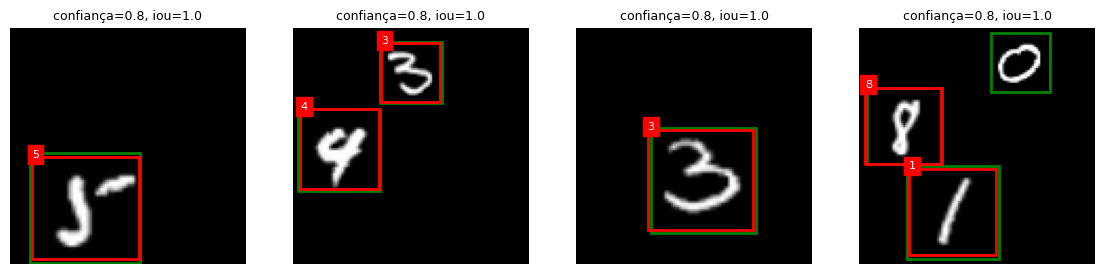

confiança=0.9, iou=0.3: 453 caixas


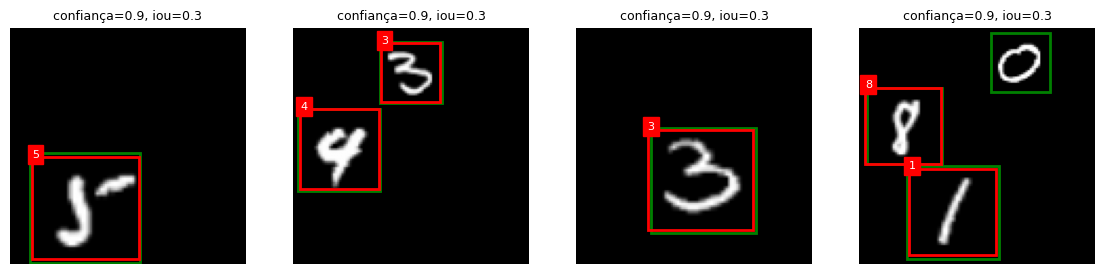

confiança=0.9, iou=0.5: 453 caixas


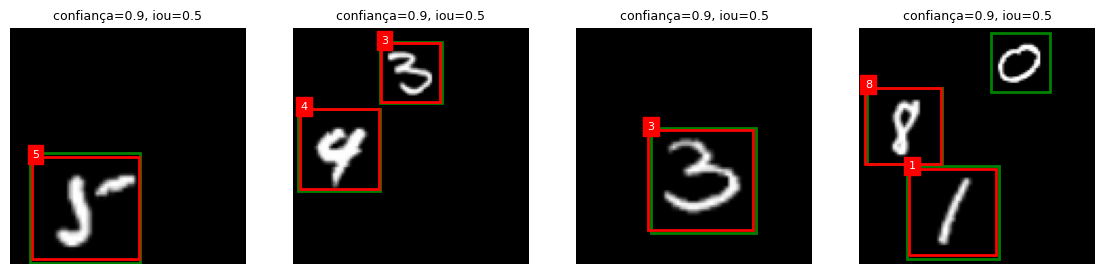

confiança=0.9, iou=0.75: 453 caixas


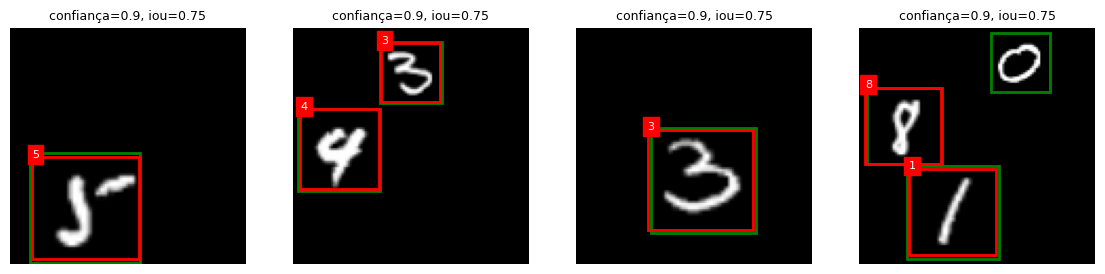

confiança=0.9, iou=1.0: 453 caixas


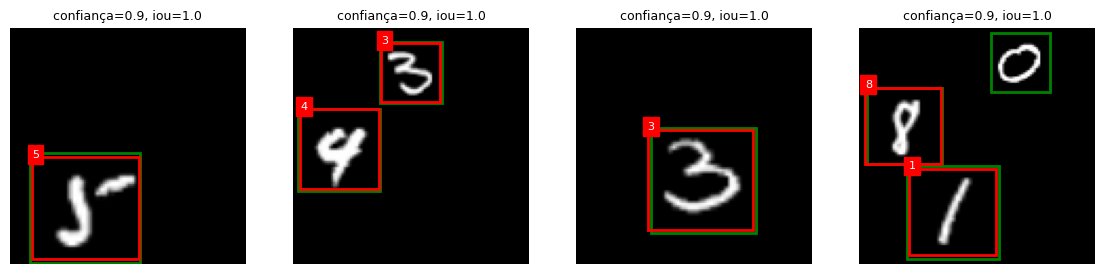

In [28]:
confidence_thresholds = [0.1, 0.5, 0.8, 0.9]
iou_thresholds = [0.3, 0.5, 0.75, 1.0]

num_true_boxes = sum(len(grid_to_boxes(target)) for target in targets) # soma da quantidade de caixas
print(f"{num_true_boxes} dígitos de verdade no lote\n")

for confidence_threshold in confidence_thresholds:
    for iou_threshold in iou_thresholds:
        detections = detect(model, images,
                            threshold=confidence_threshold,
                            iou_threshold=iou_threshold)
        num_detected_boxes = sum(len(boxes) for boxes in detections)
        print(f"confiança={confidence_threshold}, iou={iou_threshold}: "
              f"{num_detected_boxes} caixas")

        fig, axes = plt.subplots(1, 4, figsize=(14, 4))
        for img_index, ax in enumerate(axes):
            ax.imshow(images[img_index, 0], cmap="gray")
            draw_boxes(ax, grid_to_boxes(targets[img_index]), "green", show_labels=False)
            draw_boxes(ax, detections[img_index], "red")
            ax.set_title(f"confiança={confidence_threshold}, iou={iou_threshold}", fontsize=9)
            ax.axis("off")
        plt.show()


Apos analisar os resultados dispostos na tabela a seguir:
| confiança | iou=0.3 | iou=0.5 | iou=0.75 | iou=1.0 |
|---|---|---|---|---|
| 0.1 | 512 | 512 | 517 | 587 |
| 0.5 | 504 | 504 | 506 | 513 |
| 0.8 | 476 | 476 | 476 | 476 |
| 0.9 | 454 | 454 | 454 | 454 |

Após analisar os resultados apresentados na tabela, observo que quanto menor o threshold de confiança, maior é a quantidade de caixas detectadas. Também é possível notar que, para valores mais altos de confiança, a variação no número de caixas em relação ao threshold de IoU se torna praticamente nula, tornando-o pouco relevante nesses casos. Já para valores menores de confiança, como 0.1 e 0.5, o threshold de IoU apresenta maior impacto na quantidade de caixas detectadas que costuma ser maior.


### Exercício 2: uma grade mais fina

Troque a grade para $S = 14$. Quantos blocos de pooling a rede precisa ter? Ajuste o `Detector`, treine de novo e compare os resultados.


Vão ser necessários 3 blocos de pooling, pois cada um divide o tamanho da imagem por 2 , ( 112 -> 56 -> 28 -> 14 ), pra chegar na grade S = 14.

In [29]:
S = 14

# novo detector
class DetectorS14(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(1, 16), # [N, 16, 56, 56]
            conv_block(16, 32), # [N, 32, 28, 28]
            conv_block(32, 64), # [N, 64, 14, 14]
        )
        self.head = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1), # [N, 128, 14, 14]
            nn.ReLU(),
            nn.Conv2d(128, 5 + NUM_CLASSES, kernel_size=1), # [N, 15, 14, 14]
        )

    def forward(self, x):
        x = self.head(self.features(x))
        return x.permute(0, 2, 3, 1) # [N, 14, 14, 15]

# novos conjuntos de treino 14
train_set_s14 = SyntheticMNIST(mnist_train, num_images=20000, seed=0)
test_set_s14 = SyntheticMNIST(mnist_test, num_images=1000, seed=1)

train_dataloader_s14 = DataLoader(train_set_s14, batch_size=64, shuffle=True, num_workers=2)
test_dataloader_s14 = DataLoader(test_set_s14, batch_size=200)

# Validar formato de saída
model_s14 = DetectorS14().to(device)
images_batch, targets_batch = next(iter(train_dataloader_s14))
print("Saida Shape:", model_s14(images_batch.to(device)).shape)

Saida Shape: torch.Size([64, 14, 14, 15])


A seguir o treinamento do modelo adaptado pra a grade de $14 \times 14$.

[1/10] perda 5.490
[2/10] perda 2.021
[3/10] perda 1.676
[4/10] perda 1.510
[5/10] perda 1.403
[6/10] perda 1.326
[7/10] perda 1.246
[8/10] perda 1.189
[9/10] perda 1.148
[10/10] perda 1.080


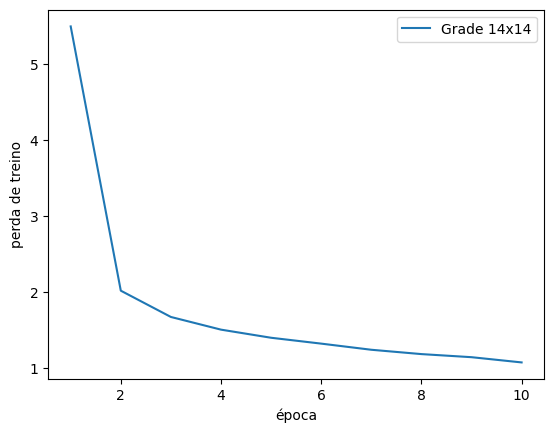

In [30]:
torch.manual_seed(42)
losses_s14 = train(model_s14, train_dataloader_s14, num_epochs=10)

plt.plot(range(1, 11), losses_s14, label="Grade 14x14")
plt.xlabel("época")
plt.ylabel("perda de treino")
plt.legend()
plt.show()

Abaixo segue os resultados do novo detector na grade de $14 \times 14$.

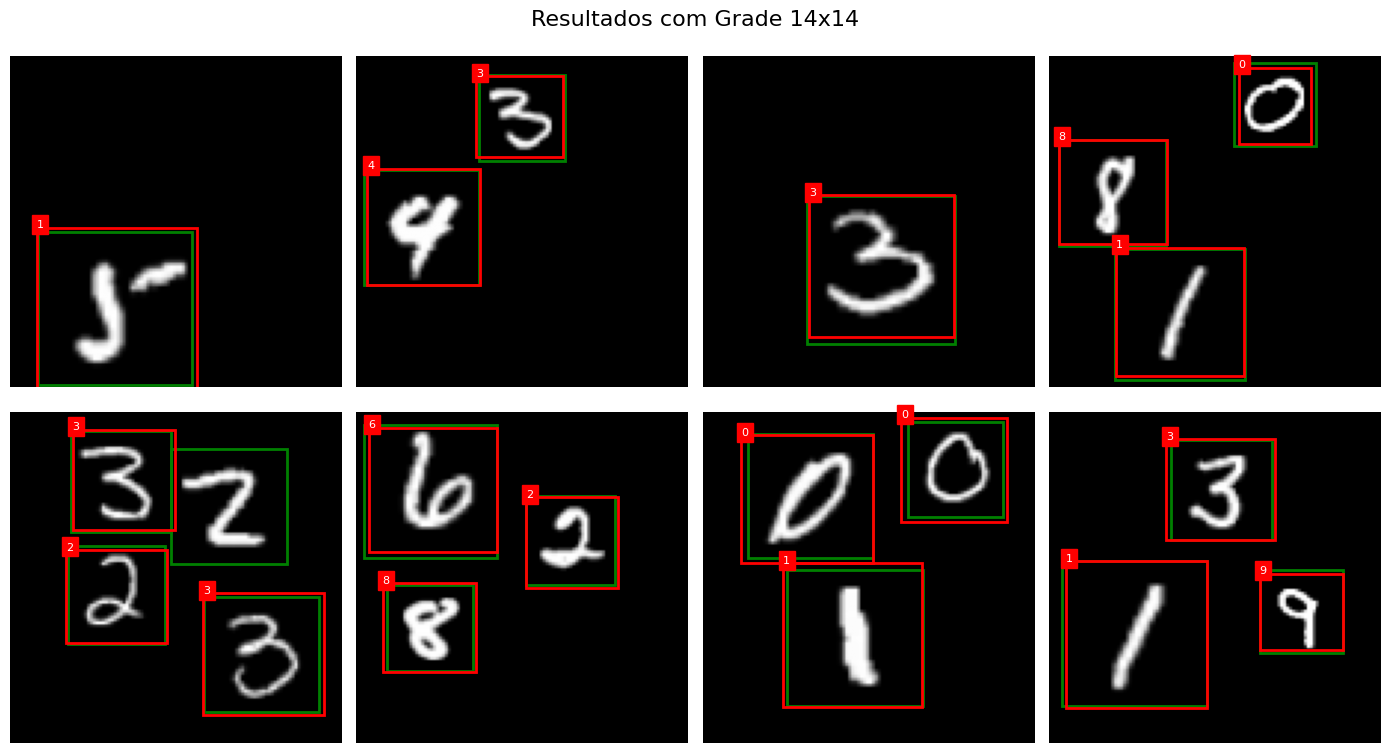

In [31]:
images, targets = next(iter(test_dataloader_s14))
detections_s14 = detect(model_s14, images)

fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
for k, ax in enumerate(axes.flat):
    ax.imshow(images[k, 0], cmap="gray")
    draw_boxes(ax, grid_to_boxes(targets[k]), "green", show_labels=False)
    draw_boxes(ax, detections_s14[k], "red")
    ax.axis("off")
plt.tight_layout()
plt.suptitle("Resultados com Grade 14x14", fontsize=16, y=1.02)
plt.show()


### Exercício 3: dígitos sobrepostos

Mude a `make_image` para permitir que os dígitos se sobreponham, usando `torch.maximum` para colar o dígito sem apagar o que já está na imagem. O que acontece quando dois centros caem na mesma célula? Quantas caixas a `boxes_to_grid` perde?

In [32]:
def make_image(mnist, rng, max_digits=4):
    image = torch.zeros(1, IMAGE_SIZE, IMAGE_SIZE)
    boxes = []    # (classe, x, y, w, h) entre 0 e 1

    n_digits = rng.randint(1, max_digits)
    for _ in range(n_digits):
        size = rng.randint(28, 56)
        x0 = rng.randint(0, IMAGE_SIZE - size)
        y0 = rng.randint(0, IMAGE_SIZE - size)

        digit, label = mnist[rng.randrange(len(mnist))]                             # [1, 28, 28]
        digit = F.interpolate(digit[None], size=(size, size), mode="bilinear")[0]   # [1, size, size]

        region = image[:, y0:y0 + size, x0:x0 + size]
        image[:, y0:y0 + size, x0:x0 + size] = torch.maximum(region, digit)

        x = (x0 + size / 2) / IMAGE_SIZE
        y = (y0 + size / 2) / IMAGE_SIZE
        boxes.append((label, x, y, size / IMAGE_SIZE, size / IMAGE_SIZE))

    return image, boxes

In [38]:
import random
rng = random.Random(42)

total_boxes = 0
lost_boxes = 0

for _, boxes in (make_image(mnist_train, rng, max_digits=3) for _ in range(1000)):
    centros = {(int(b[2] * S), int(b[1] * S)) for b in boxes}
    lost_boxes += len(boxes) - len(centros)
    total_boxes += len(boxes)

print(f"proporção de caixas perdidas: {lost_boxes}/{total_boxes} ({100*lost_boxes/total_boxes:.1f}%)")

proporção de caixas perdidas: 7/2000 (0.3%)


Quando dois centros caem na mesma célula, uma das caixas é sobrescrita no box to grid, fazendo a rede ignorar um dos dígitos durante o treinamento. Em 1000 imagens, apenas 7 das cerca de 2000 caixas foram perdidas (0,3%), provavelmente porque as células de 8×8 são pequenas. Com uma grade menor, essa perda seria maior, podendo ser evitada se cada célula previsse mais de uma caixa.